In [ ]:
# Import libraries
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import datetime
import sqlite3
import numpy as np
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Import the data

> https://www.transtats.bts.gov/OT_Delay/OT_DelayCause1.asp

Navigate to "Database Tables" > Reporting Carrier On-Time Performance (1987-present)

Select all fields from Year to DivDistance (inclusive) and download the dataset for August 2025 - July 2026

Alternatively, unzip data.zip and place all the csv files in /data

In [12]:
files = [ "08_2025", "09_2025", "10_2025", "11_2025", "12_2025", "01_2026", "02_2026", "03_2026", "04_2026", "05_2026", "06_2026", "07_2026" ]
flights_df = pd.DataFrame()

for name in files:
    print("Loading", name)
    loaded_df = pd.read_csv(f'./data/{name}.csv', dtype={48: str})
    flights_df = pd.concat([flights_df, loaded_df], verify_integrity=False)

flights_df.to_csv("./data/flights.csv")

Loading 08_2025
Loading 09_2025


ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

# Cleaning the Data Pt. 1

First we need to load our data. Then, we can take a look at what values are NaN.

In [3]:
flights_df = pd.read_csv("./data/flights.csv", dtype={49: str}, index_col=0)

display(flights_df.head(5))
flights_df.isna().sum()

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
0,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,28,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,2252,2253.0,1.0,1.0,0.0,0.0,2200-2259,16.0,2309.0,658.0,8.0,729,706.0,-23.0,0.0,0.0,-2.0,0700-0759,0.0,NaN,0.0,337.0,313.0,289.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
1,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,302,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,1745,1734.0,-11.0,0.0,0.0,-1.0,1700-1759,41.0,1815.0,2042.0,9.0,2056,2051.0,-5.0,0.0,0.0,-1.0,2000-2059,0.0,NaN,0.0,371.0,377.0,327.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N101NN,307,12892,1289209,32575,LAX,"Los Angeles, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,745,746.0,1.0,1.0,0.0,0.0,0700-0759,14.0,800.0,1542.0,24.0,1625,1606.0,-19.0,0.0,0.0,-2.0,1600-1659,0.0,NaN,0.0,340.0,320.0,282.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
3,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N102NN,166,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,1317,1309.0,-8.0,0.0,0.0,-1.0,1300-1359,25.0,1334.0,2119.0,8.0,2159,2127.0,-32.0,0.0,0.0,-2.0,2100-2159,0.0,NaN,0.0,342.0,318.0,285.0,1.0,2586.0,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
4,2025,3,8,1,5,8/1/2025 12:00:00 AM,AA,19805,AA,N102NN,179,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,800,753.0,-7.0,0.0,0.0,-1.0,0800-0859,27.0,820.0,1108.0,11.0,1132,1119.0,-13.0,0.0,0.0,-1.0,1100-1159,0.0,NaN,0.0,392.0,386.0,348.0,1.0,2586.0,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN


YEAR                             0
QUARTER                          0
MONTH                            0
DAY_OF_MONTH                     0
DAY_OF_WEEK                      0
FL_DATE                          0
OP_UNIQUE_CARRIER                0
OP_CARRIER_AIRLINE_ID            0
OP_CARRIER                       0
TAIL_NUM                     17774
OP_CARRIER_FL_NUM                0
ORIGIN_AIRPORT_ID                0
ORIGIN_AIRPORT_SEQ_ID            0
ORIGIN_CITY_MARKET_ID            0
ORIGIN                           0
ORIGIN_CITY_NAME                 0
ORIGIN_STATE_ABR                 0
ORIGIN_STATE_FIPS                0
ORIGIN_STATE_NM                  0
ORIGIN_WAC                       0
DEST_AIRPORT_ID                  0
DEST_AIRPORT_SEQ_ID              0
DEST_CITY_MARKET_ID              0
DEST                             0
DEST_CITY_NAME                   0
DEST_STATE_ABR                   0
DEST_STATE_FIPS                  0
DEST_STATE_NM                    0
DEST_WAC            

We are examining flights based on their departure and arrival time, so if neither are available we can safely discard them since no data was recorded. There are only a small number of these (< 1%)

We can also fix the delay type fields since they are filled with NaN instead of 0 for no delay.

In [4]:
flights_df.dropna(subset=['DEP_TIME', 'ARR_TIME'], inplace=True) # Drop flights with no departure or arrival time, data was not published (small number)
flights_df['CARRIER_DELAY'] = flights_df['CARRIER_DELAY'].fillna(0) # NaN is no delay
flights_df['WEATHER_DELAY'] = flights_df['WEATHER_DELAY'].fillna(0) # NaN is no delay
flights_df['NAS_DELAY'] = flights_df['NAS_DELAY'].fillna(0) # NaN is no delay
flights_df['SECURITY_DELAY'] = flights_df['SECURITY_DELAY'].fillna(0) # NaN is no delay
flights_df['LATE_AIRCRAFT_DELAY'] = flights_df['LATE_AIRCRAFT_DELAY'].fillna(0) # NaN is no delay

print(flights_df.isna().sum())
display(flights_df[flights_df['DIV_AIRPORT_LANDINGS'].isna()])
print(flights_df['DIV_AIRPORT_LANDINGS'].value_counts(dropna=False))

YEAR                             0
QUARTER                          0
MONTH                            0
DAY_OF_MONTH                     0
DAY_OF_WEEK                      0
FL_DATE                          0
OP_UNIQUE_CARRIER                0
OP_CARRIER_AIRLINE_ID            0
OP_CARRIER                       0
TAIL_NUM                         0
OP_CARRIER_FL_NUM                0
ORIGIN_AIRPORT_ID                0
ORIGIN_AIRPORT_SEQ_ID            0
ORIGIN_CITY_MARKET_ID            0
ORIGIN                           0
ORIGIN_CITY_NAME                 0
ORIGIN_STATE_ABR                 0
ORIGIN_STATE_FIPS                0
ORIGIN_STATE_NM                  0
ORIGIN_WAC                       0
DEST_AIRPORT_ID                  0
DEST_AIRPORT_SEQ_ID              0
DEST_CITY_MARKET_ID              0
DEST                             0
DEST_CITY_NAME                   0
DEST_STATE_ABR                   0
DEST_STATE_FIPS                  0
DEST_STATE_NM                    0
DEST_WAC            

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
27791,2026,3,7,2,4,7/2/2026 12:00:00 AM,F9,20436,F9,N638FR,2791,13204,1320403,31454,MCO,"Orlando, FL",FL,12,Florida,33,13930,1393008,30977,ORD,"Chicago, IL",IL,17,Illinois,41,2101,2052.0,-9.0,0.0,0.0,-1.0,2100-2159,13.0,2105.0,302.0,17.0,2319,319.0,240.0,240.0,1.0,12.0,2300-2359,0.0,NaN,0.0,198.0,447.0,417.0,1.0,1005.0,5,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


DIV_AIRPORT_LANDINGS
0.0    6895391
1.0      17501
9.0        118
2.0        104
3.0          2
NaN          1
Name: count, dtype: int64


There is still one flight that has a NaN number of airport landings. It looks like this flight has no diversion data anyways, so it did not divert. The standard value for this is 0, not NaN, so we can correct it.

In [5]:
flights_df['DIV_AIRPORT_LANDINGS'] = flights_df['DIV_AIRPORT_LANDINGS'].fillna(0)
print(flights_df['DIV_AIRPORT_LANDINGS'].value_counts(dropna=False))

DIV_AIRPORT_LANDINGS
0.0    6895392
1.0      17501
9.0        118
2.0        104
3.0          2
Name: count, dtype: int64


Let's parse our data now! First, we need to look at what types we're working with.

In [6]:
print(flights_df.dtypes)
display(flights_df.sample(10))

YEAR                         int64
QUARTER                      int64
MONTH                        int64
DAY_OF_MONTH                 int64
DAY_OF_WEEK                  int64
FL_DATE                     object
OP_UNIQUE_CARRIER           object
OP_CARRIER_AIRLINE_ID        int64
OP_CARRIER                  object
TAIL_NUM                    object
OP_CARRIER_FL_NUM            int64
ORIGIN_AIRPORT_ID            int64
ORIGIN_AIRPORT_SEQ_ID        int64
ORIGIN_CITY_MARKET_ID        int64
ORIGIN                      object
ORIGIN_CITY_NAME            object
ORIGIN_STATE_ABR            object
ORIGIN_STATE_FIPS            int64
ORIGIN_STATE_NM             object
ORIGIN_WAC                   int64
DEST_AIRPORT_ID              int64
DEST_AIRPORT_SEQ_ID          int64
DEST_CITY_MARKET_ID          int64
DEST                        object
DEST_CITY_NAME              object
DEST_STATE_ABR              object
DEST_STATE_FIPS              int64
DEST_STATE_NM               object
DEST_WAC            

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_AIRLINE_ID,OP_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DELAY_NEW,DEP_DEL15,DEP_DELAY_GROUP,DEP_TIME_BLK,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DELAY_NEW,ARR_DEL15,ARR_DELAY_GROUP,ARR_TIME_BLK,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,FIRST_DEP_TIME,TOTAL_ADD_GTIME,LONGEST_ADD_GTIME,DIV_AIRPORT_LANDINGS,DIV_REACHED_DEST,DIV_ACTUAL_ELAPSED_TIME,DIV_ARR_DELAY,DIV_DISTANCE
75771,2026,1,1,4,7,1/4/2026 12:00:00 AM,YX,20452,YX,N213JQ,5628,12339,1233904,32337,IND,"Indianapolis, IN",IN,18,Indiana,42,10721,1072103,30721,BOS,"Boston, MA",MA,25,Massachusetts,13,1600,1556.0,-4.0,0.0,0.0,-1.0,1600-1659,13.0,1609.0,1756.0,9.0,1825,1805.0,-20.0,0.0,0.0,-2.0,1800-1859,0.0,NaN,0.0,145.0,129.0,107.0,1.0,818.0,4,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
126712,2025,3,9,7,7,9/7/2025 12:00:00 AM,WN,19393,WN,N8734Q,282,12173,1217305,32134,HNL,"Honolulu, HI",HI,15,Hawaii,2,12758,1275805,32758,KOA,"Kona, HI",HI,15,Hawaii,2,2030,2025.0,-5.0,0.0,0.0,-1.0,2000-2059,12.0,2037.0,2108.0,4.0,2120,2112.0,-8.0,0.0,0.0,-1.0,2100-2159,0.0,NaN,0.0,50.0,47.0,31.0,1.0,163.0,1,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
376694,2025,4,11,20,4,11/20/2025 12:00:00 AM,YX,20452,YX,N209JQ,5646,12451,1245103,31136,JAX,"Jacksonville, FL",FL,12,Florida,33,12953,1295304,31703,LGA,"New York, NY",NY,36,New York,22,600,559.0,-1.0,0.0,0.0,-1.0,0600-0659,18.0,617.0,813.0,8.0,825,821.0,-4.0,0.0,0.0,-1.0,0800-0859,0.0,NaN,0.0,145.0,142.0,116.0,1.0,834.0,4,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
450850,2026,2,6,23,2,6/23/2026 12:00:00 AM,DL,19790,DL,N133DU,2963,13487,1348702,31650,MSP,"Minneapolis, MN",MN,27,Minnesota,63,11278,1127805,30852,DCA,"Washington, DC",VA,51,Virginia,38,1438,1442.0,4.0,4.0,0.0,0.0,1400-1459,17.0,1459.0,1758.0,12.0,1809,1810.0,1.0,1.0,0.0,0.0,1800-1859,0.0,NaN,0.0,151.0,148.0,119.0,1.0,931.0,4,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
432234,2025,3,8,22,5,8/22/2025 12:00:00 AM,WN,19393,WN,N8579Z,3322,14771,1477104,32457,SFO,"San Francisco, CA",CA,6,California,91,15016,1501606,31123,STL,"St. Louis, MO",MO,29,Missouri,64,1125,1206.0,41.0,41.0,1.0,2.0,1100-1159,16.0,1222.0,1744.0,4.0,1720,1748.0,28.0,28.0,1.0,1.0,1700-1759,0.0,NaN,0.0,235.0,222.0,202.0,1.0,1735.0,7,12.0,0.0,0.0,0.0,16.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
373995,2025,3,9,21,7,9/21/2025 12:00:00 AM,AA,19805,AA,N885NN,624,10721,1072103,30721,BOS,"Boston, MA",MA,25,Massachusetts,13,11057,1105704,31057,CLT,"Charlotte, NC",NC,37,North Carolina,36,550,551.0,1.0,1.0,0.0,0.0,0001-0559,15.0,606.0,750.0,10.0,818,800.0,-18.0,0.0,0.0,-2.0,0800-0859,0.0,NaN,0.0,148.0,129.0,104.0,1.0,728.0,3,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
289672,2025,3,9,16,2,9/16/2025 12:00:00 AM,OO,20304,OO,N305SY,4029,13851,1385104,33851,OKC,"Oklahoma City, OK",OK,40,Oklahoma,73,14869,1486903,34614,SLC,"Salt Lake City, UT",UT,49,Utah,87,845,1140.0,175.0,175.0,1.0,11.0,0800-0859,12.0,1152.0,1301.0,5.0,1015,1306.0,171.0,171.0,1.0,11.0,1000-1059,0.0,NaN,0.0,150.0,146.0,129.0,1.0,866.0,4,171.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
455173,2025,3,8,24,7,8/24/2025 12:00:00 AM,AS,19930,AS,N290AK,485,10994,1099402,30994,CHS,"Charleston, SC",SC,45,South Carolina,37,14747,1474703,30559,SEA,"Seattle, WA",WA,53,Washington,93,1817,1809.0,-8.0,0.0,0.0,-1.0,1800-1859,10.0,1819.0,2112.0,10.0,2103,2122.0,19.0,19.0,1.0,1.0,2100-2159,0.0,NaN,0.0,346.0,373.0,353.0,1.0,2415.0,10,0.0,0.0,19.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
1477

Our FL_DATE is a string, not a date object. It also does not include the departure time. Let's convert it using the individual components after we verify their ranges make sense, and add it to a column named "SCHEDULED_DATE". We should use CRS_DEP_TIME (formatted hhmm) since we want to know the scheduled time before any delays.

Unfortunately, this data is also messy and does not follow the format exactly. Instead, we will need to format the values (1 to 2359) by padding them with leading 0s to match the format. For example: 1 should become 0001 (or 00:01)

In [7]:
def create_date(row):
    return datetime.datetime(row['YEAR'], row['MONTH'], row['DAY_OF_MONTH'], hour=int(row['CRS_DEP_TIME'][:2]), minute=int(row['CRS_DEP_TIME'][2:]))

# Look at current distribution
print("Departure Time:", flights_df['CRS_DEP_TIME'].min(), "-", flights_df['CRS_DEP_TIME'].max())
print("Year:", flights_df['YEAR'].min(), "-", flights_df['YEAR'].max())
print("Month:", flights_df['MONTH'].min(), "-", flights_df['MONTH'].max())
print("Day:", flights_df['DAY_OF_MONTH'].min(), "-", flights_df['DAY_OF_MONTH'].max())

# Clean up the departure time
flights_df['CRS_DEP_TIME'] = flights_df['CRS_DEP_TIME'].astype(str).apply(lambda x: x.zfill(4))
print(flights_df['CRS_DEP_TIME'].sample(10))

# Convert to date
flights_df.drop(columns=['FL_DATE'], inplace=True)
flights_df['DATE'] = flights_df.apply(create_date, axis=1)
display(flights_df[['DATE', 'CRS_DEP_TIME']].sample(10))

Departure Time: 1 - 2359
Year: 2025 - 2026
Month: 1 - 12
Day: 1 - 31
60156     1935
270843    1340
112627    0710
300074    1402
154281    2025
36099     0705
460689    1816
280164    1850
155727    1115
181948    1209
Name: CRS_DEP_TIME, dtype: object


,DATE,CRS_DEP_TIME
95327,2026-02-06 12:24:00,1224
205312,2026-04-11 18:59:00,1859
527106,2026-03-27 08:32:00,0832
361174,2026-06-18 17:45:00,1745
100513,2025-11-06 13:00:00,1300
407152,2025-09-22 15:25:00,1525
60610,2026-07-03 13:14:00,1314
479292,2025-09-26 13:00:00,1300
11668,2026-03-01 12:41:00,1241
513471,2025-10-27 05:02:00,0502


The rest of the data is parsed correctly, so we can continue with exporting this to a database!

# Exporting to a Database

We will now export all of our data to an sqlite file using ``to_sql`` to the "Flights" table

In [8]:
conn = sqlite3.connect("database.sqlite")

flights_df.to_sql(name='Flights', con=conn, if_exists='replace')

6913117

Let's verify that our table is setup correctly:

In [9]:
crsr = conn.cursor()
query = "PRAGMA table_info(Flights)"
print(crsr.execute(query).fetchall())

query = "SELECT COUNT(*) FROM Flights"
print("Database Rows:", crsr.execute(query).fetchall()[0][0])
print("DataFrame Rows:", flights_df.shape[0])

[(0, 'index', 'INTEGER', 0, None, 0), (1, 'YEAR', 'INTEGER', 0, None, 0), (2, 'QUARTER', 'INTEGER', 0, None, 0), (3, 'MONTH', 'INTEGER', 0, None, 0), (4, 'DAY_OF_MONTH', 'INTEGER', 0, None, 0), (5, 'DAY_OF_WEEK', 'INTEGER', 0, None, 0), (6, 'OP_UNIQUE_CARRIER', 'TEXT', 0, None, 0), (7, 'OP_CARRIER_AIRLINE_ID', 'INTEGER', 0, None, 0), (8, 'OP_CARRIER', 'TEXT', 0, None, 0), (9, 'TAIL_NUM', 'TEXT', 0, None, 0), (10, 'OP_CARRIER_FL_NUM', 'INTEGER', 0, None, 0), (11, 'ORIGIN_AIRPORT_ID', 'INTEGER', 0, None, 0), (12, 'ORIGIN_AIRPORT_SEQ_ID', 'INTEGER', 0, None, 0), (13, 'ORIGIN_CITY_MARKET_ID', 'INTEGER', 0, None, 0), (14, 'ORIGIN', 'TEXT', 0, None, 0), (15, 'ORIGIN_CITY_NAME', 'TEXT', 0, None, 0), (16, 'ORIGIN_STATE_ABR', 'TEXT', 0, None, 0), (17, 'ORIGIN_STATE_FIPS', 'INTEGER', 0, None, 0), (18, 'ORIGIN_STATE_NM', 'TEXT', 0, None, 0), (19, 'ORIGIN_WAC', 'INTEGER', 0, None, 0), (20, 'DEST_AIRPORT_ID', 'INTEGER', 0, None, 0), (21, 'DEST_AIRPORT_SEQ_ID', 'INTEGER', 0, None, 0), (22, 'DEST_CIT

Now that our data is in our database, we can cleanup the dataframe from memory and continue!

In [10]:
flights_df = None
conn.close()

# Data Exploration & Summary Statistics

## Exploring Arrival Delays

We will explore arrival delays (arr_delay), the delay people really care about when their flight is delayed.

In [5]:
conn = sqlite3.connect("database.sqlite")
crsr = conn.cursor()

query = "SELECT COUNT(arr_delay) FROM Flights"
crsr.execute(query).fetchall()

[(6895510,)]

This is a lot of entries! Let's take a random sample of 100,000 flights to do some basic analysis on.

In [ ]:
flights_df = pd.read_sql_query("SELECT arr_delay, diverted, op_carrier FROM Flights ORDER BY RANDOM() LIMIT 100000;", conn)

print(flights_df.describe())
flights_df[flights_df['ARR_DELAY'].isna()].head(10)

          ARR_DELAY       DIVERTED
count  99740.000000  100000.000000
mean       8.415821       0.002600
std       63.794052       0.050924
min      -84.000000       0.000000
25%      -16.000000       0.000000
50%       -6.000000       0.000000
75%       11.000000       0.000000
max     2389.000000       1.000000


,ARR_DELAY,DIVERTED,OP_CARRIER
862,NaN,1.0,OH
1575,NaN,1.0,AA
1807,NaN,1.0,AA
1953,NaN,1.0,AA
2157,NaN,1.0,DL
2641,NaN,1.0,YX
2989,NaN,1.0,OO
3223,NaN,1.0,DL
3897,NaN,1.0,AA
4137,NaN,1.0,UA


We have a problem, some of the arrival delays are NaN! In this dataset, this looks related to the flight being diverted and not arriving at its destination. Let's confirm.

In [ ]:
flights_df[(flights_df['ARR_DELAY'].isna()) & (flights_df['DIVERTED'] != 1)].head(10)

,ARR_DELAY,DIVERTED,OP_CARRIER


This theory is correct! For our analysis of the delay, let's only look at flights that actually arrived.

In [ ]:
flights_df = pd.read_sql_query("SELECT arr_delay, diverted, op_carrier FROM Flights WHERE diverted == 0;", conn)
flights_df.describe()

,ARR_DELAY,DIVERTED
count,6.895510e+06,6895510.0
mean,8.111811e+00,0.0
std,6.065110e+01,0.0
min,-1.090000e+02,0.0
25%,-1.600000e+01,0.0
50%,-6.000000e+00,0.0
75%,1.100000e+01,0.0
max,4.336000e+03,0.0


Some of our delays are negative. According to the dataset, this means that they arrived early! Let's plot this data to draw some more conclusions.

Text(0.5, 1.0, 'Arrival Delays by Carrier')

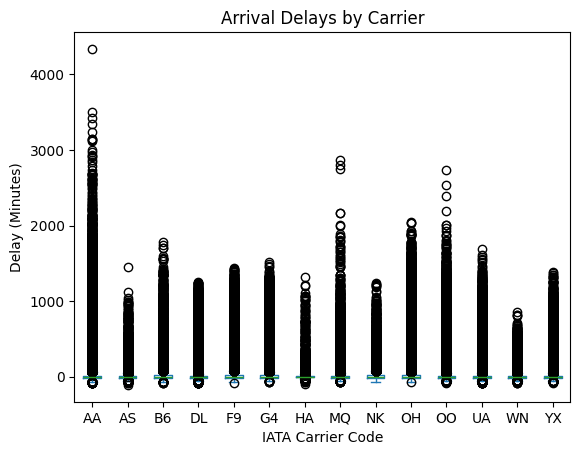

In [ ]:
boxplot = flights_df.plot.box(column="ARR_DELAY", by="OP_CARRIER").iloc[0]
boxplot.set_xlabel("IATA Carrier Code")
boxplot.set_ylabel("Delay (Minutes)")
boxplot.set_title("Arrival Delays by Carrier")

It looks like this dataset has a lot of outliers, creating a lot of circles on our box plot! One flight was also delayed for about 3 days, something really bad must have happened. This is not very useful for drawing many conclusions since there are many large values. Let's use a logarithmic scale to take a closer look. Since we do have negative and zero values, we will use symlog.

{'whiskers': [<matplotlib.lines.Line2D object at 0x000001DAA55FCCD0>, <matplotlib.lines.Line2D object at 0x000001DAA50AE830>, <matplotlib.lines.Line2D object at 0x000001DAA50AE710>, <matplotlib.lines.Line2D object at 0x000001DAA50AF820>, <matplotlib.lines.Line2D object at 0x000001DAA50AFDF0>, <matplotlib.lines.Line2D object at 0x000001DAA50AE5F0>, <matplotlib.lines.Line2D object at 0x000001DAA5C2B9A0>, <matplotlib.lines.Line2D object at 0x000001DAA5C28250>, <matplotlib.lines.Line2D object at 0x000001DAA50CB7C0>, <matplotlib.lines.Line2D object at 0x000001DAA50CAD10>, <matplotlib.lines.Line2D object at 0x000001DAA50CA8C0>, <matplotlib.lines.Line2D object at 0x000001DAA50CAEC0>, <matplotlib.lines.Line2D object at 0x000001DAA50CA710>, <matplotlib.lines.Line2D object at 0x000001DAA4D1CCA0>, <matplotlib.lines.Line2D object at 0x000001DAA4D1EF80>, <matplotlib.lines.Line2D object at 0x000001DAA4D1E5C0>, <matplotlib.lines.Line2D object at 0x000001DAA4D1E230>, <matplotlib.lines.Line2D object at

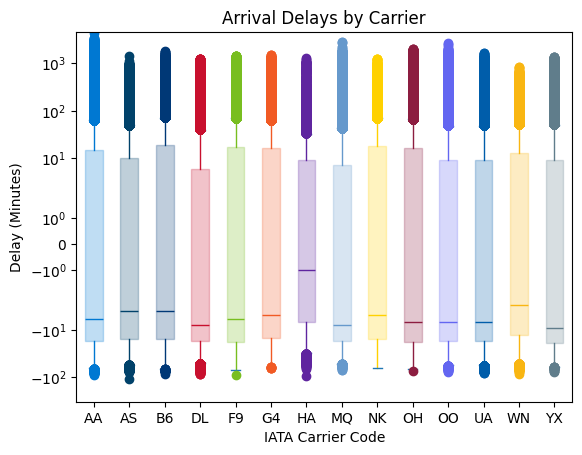

In [ ]:
carrier_colors = {
    "AA": "#0078D2",
    "AS": "#01426A",
    "B6": "#003876",
    "DL": "#C8102E",
    "F9": "#78BE20",
    "G4": "#F15A24",
    "HA": "#5F259F",
    "MQ": "#6699CC",
    "NK": "#FFD100",
    "OH": "#8C1D40",
    "OO": "#6366F1",
    "UA": "#005DAA",
    "WN": "#F9B612",
    "YX": "#607D8B"
}

boxplot = flights_df.plot.box(column="ARR_DELAY", by="OP_CARRIER", return_type="dict", patch_artist=True).iloc[0]
plt.xlabel("IATA Carrier Code")
plt.ylabel("Delay (Minutes)")
plt.title("Arrival Delays by Carrier")
plt.yscale('symlog')

# Make it pretty!
for i, color in enumerate(carrier_colors.values()):
    box = boxplot['boxes'][i]
    median = boxplot['medians'][i]
    fliers = boxplot['fliers'][i]

    box.set_color(color)
    box.set_alpha(0.25)
    median.set_color(color)
    fliers.set_markerfacecolor(color)
    fliers.set_markeredgecolor(color)

    # Set every 2 whiskers color
    for whisker in boxplot['whiskers'][2*i : 2*i + 2]:
        whisker.set_color(color)

plt.show()

The median arrival delay will be the most important here since we do have a lot of outlier data. The median delay is negative, indicating that most flights arrive early across carriers. 75% of flights have a delay of around 10 minutes or less across carriers as well.

American Airlines (AA) does have more outlier delays extending beyond 1,000 minutes than the other carriers. There are enough outliers across carriers that it is unlikely these datapoints were incorrectly entered, there may have been some event preventing them from taking off for more than a day.

## Confidence Intervals

This subsection explores Confidence Intervals to find some statistical measure for expected delays over a time interval. This statistical measure is useful for comparing a range of mean values instead of singular hypothesees.

However, with such a large dataset, you require preprocessing in order to come up with some realistic conclusion.



In [8]:
# 99% confidence intervals for arrival delay (minutes) and P(delay >= 15 min) by scheduled departure hour

query = "SELECT DATE, ARR_DELAY, ARR_DEL15 FROM Flights WHERE DIVERTED = 0 AND ARR_DELAY IS NOT NULL"
timestamp_delay = pd.read_sql_query(query, conn, parse_dates=['DATE'])
timestamp_delay['hour'] = timestamp_delay['DATE'].dt.hour

hourly = timestamp_delay.groupby('hour').agg(count=('ARR_DELAY', 'count'),
                                             mean=('ARR_DELAY', 'mean'),
                                             median=('ARR_DELAY', 'median'),
                                             q1=('ARR_DELAY', lambda x: x.quantile(0.25)),
                                             q3=('ARR_DELAY', lambda x: x.quantile(0.75)),
                                             std=('ARR_DELAY', 'std'),
                                             pct_late=('ARR_DEL15', 'mean'))  # mean of 0/1 = proportion late
hourly['iqr'] = hourly['q3'] - hourly['q1']

# 99% CI for mean delay
se = hourly['std'] / np.sqrt(hourly['count'])
hourly['99%_lower_bound'] = hourly['mean'] - 2.576 * se
hourly['99%_upper_bound'] = hourly['mean'] + 2.576 * se

# 99% CI for P(delay >= 15 min)
p_se = np.sqrt(hourly['pct_late'] * (1 - hourly['pct_late']) / hourly['count'])
hourly['pct_late_lower'] = hourly['pct_late'] - 2.576 * p_se
hourly['pct_late_upper'] = hourly['pct_late'] + 2.576 * p_se
#pct_late_lower and pct_late_upper mean its 15+ minutes late between pct_late_lower * 100 and pct_late_upper *100 percent of the time.
#with 99% confidence.
display(hourly)



,count,mean,median,q1,q3,std,pct_late,iqr,99%_lower_bound,99%_upper_bound,pct_late_lower,pct_late_upper
hour,,,,,,,,,,,,
0,10160,1.342913,-11.0,-21.0,5.00,63.202920,0.168209,26.00,-0.272323,2.958150,0.158649,0.177768
1,3344,3.582835,-11.0,-22.0,6.00,75.568875,0.185407,28.00,0.216513,6.949157,0.168095,0.202719
2,1251,1.358913,-12.0,-23.0,8.00,62.131370,0.204636,31.00,-3.166187,5.884012,0.175254,0.234019
3,654,4.663609,-9.0,-19.0,6.75,70.003063,0.198777,25.75,-2.387770,11.714987,0.158578,0.238976
4,165,3.957576,-11.0,-19.0,5.00,55.169843,0.175758,24.00,-7.106258,15.021409,0.099429,0.252086
5,188230,-3.504038,-12.0,-20.0,-3.00,58.517411,0.083127,17.00,-3.851483,-3.156592,0.081488,0.084766
6,473284,-2.445599,-11.0,-19.0,-1.00,59.306299,0.098495,18.00,-2.667667,-2.223531,0.097379,0.099611
7,512712,-0.870949,-10.0,-18.0,1.00,54.208705,0.125376,19.00,-1.065969,-0.675929,0.124185,0.126568
8,478738,0.299968,-9.0,-18.0,3.00,50.281044,0.144323,21.00,0.112770,0.487166,0.143015,0.145632


Now that we have our dataframe: hourly, we can finally start making some conclusions.

We previously found reasonable suspicion that there is a difference in the amount of delays per hour and the length of the delays.

Here we must embolden our claims with Hypothesis Testing. First, lets see if departure time and delay duration are independent.


In [9]:
c1 = pd.crosstab(timestamp_delay['hour'], timestamp_delay['ARR_DEL15'])
chi2, p, df, _ = stats.chi2_contingency(c1)
print(f"Chi-squared = {chi2:.1f}, dof = {df}, p = {p: .3g}")

# morning (6-11) vs evening (17-22)... is the evening rate higher?
morning = timestamp_delay[timestamp_delay['hour'].between(6, 11)]['ARR_DEL15'].dropna()
evening = timestamp_delay[timestamp_delay['hour'].between(17, 22)]['ARR_DEL15'].dropna()

p_morning = morning.mean()
p_evening = evening.mean()
n_morning = len(morning)
n_evening = len(evening)

# pooled-proportion assuming that the null hypo is true... that rates are equal.
p_pool = (morning.sum() + evening.sum()) / (n_morning + n_evening)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n_morning + 1/n_evening))

z = (p_evening - p_morning) / se
p = stats.norm.sf(z)  # lets choose a 1 sided test, because that is clearly what the data is pointing to.

print(f"Morning late rate: {p_morning:.1%}, Evening late rate: {p_evening:.1%}")
print(f"z = {z:.2f}, p = {p:.3g}")


Chi-squared = 233363.2, dof = 23, p =  0
Morning late rate: 14.9%, Evening late rate: 31.1%
z = 416.00, p = 0


The important part is not the p-value but the gap between p-values between times. Because the dataset is so large, the p-values will be very small, so the difference between times is what matters.

Let's graph!

NameError: name 'Patch' is not defined

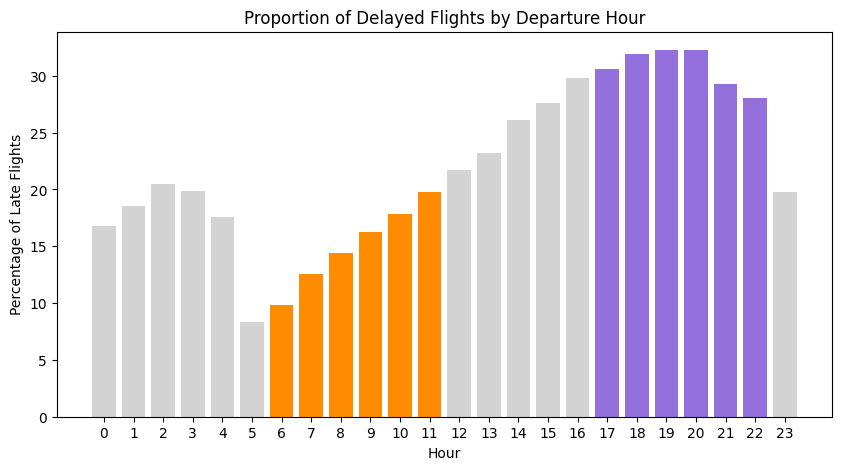

In [10]:
# Morning vs Evening Delays
segment_colors = {
    "morning": "darkorange",
    "evening": "mediumpurple",
    "other": "lightgray"
}

colors = [
    segment_colors["morning"] if 6 <= h <= 11
    else segment_colors["evening"] if 17 <= h <= 22
    else segment_colors["other"]
    for h in hourly.index
]

plt.figure(figsize=(10, 5))
plt.bar(hourly.index, hourly['pct_late'] * 100, color=colors)
plt.xticks(range(24))
plt.xlabel('Hour')
plt.ylabel('Percentage of Late Flights')
plt.title('Proportion of Delayed Flights by Departure Hour')
legend_items = [
    Patch(facecolor=segment_colors["morning"], label="Morning Flights (6-11 am)"),
    Patch(facecolor=segment_colors["evening"], label="Evening Flights (5-10 pm)"),
]
plt.legend(handles=legend_items)
plt.show()

# Medians plot with IQR band
plt.figure(figsize=(10,5))
plt.plot(hourly.index, hourly['median'], color='green', marker='o')
plt.fill_between(hourly.index, hourly['q1'], hourly['q3'], color='green', alpha=0.15, label="Middle 50% of flights (Q1-Q3)")
plt.xticks(range(24))
plt.xlabel('Hour')
plt.ylabel('Median Arrival Difference (minutes)')
plt.title('Median Difference from Expected Arrival Time by Departure Hour')
plt.legend()
plt.show()